# Análisis exploratorio y experimentos

**Proyecto:** Análisis de sentimiento de reseñas de restaurantes  
**Dataset:** [Peruvian Food Reviews](https://www.kaggle.com/datasets/lazaro97/peruvian-food-reviews) (Kaggle) — reseñas de restaurantes de Lima (Google Places y TripAdvisor, 2010–2021).

Contenido:
1. Análisis exploratorio (EDA)
2. Pipeline de NLP con ejemplos antes / después
3. Experimentos (se completa en la etapa de modelos)

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from src.nlp.preprocess import normalizar, tokenizar, quitar_stop_words, STOP_WORDS, CONSERVAR

pd.set_option("display.max_colwidth", 120)
SEMILLA = 42

## 1. Análisis exploratorio (EDA)

### 1.1 Carga y valores faltantes

In [2]:
df = pd.read_csv(RAIZ / "data" / "raw" / "reviews.csv")
print("Filas:", len(df), "| Columnas:", df.shape[1])
faltantes = df.isna().sum().to_frame("nulos")
faltantes["%"] = (faltantes["nulos"] / len(df) * 100).round(1)
faltantes

Filas: 1258435 | Columnas: 9


,nulos,%
id_review,0,0.0
review,503369,40.0
title,0,0.0
score,0,0.0
likes,0,0.0
id_nick,0,0.0
service,0,0.0
date,0,0.0
platform,0,0.0


**Hallazgo:** solo la columna `review` tiene nulos: cerca del **40 %** de las filas tienen estrellas pero no texto.  
**Decisión:** se eliminan, porque sin texto no hay nada que analizar.

In [3]:
df = df.dropna(subset=["review"])
df["review"] = df["review"].str.strip()
df = df[df["review"] != ""]
print("Reseñas con texto:", len(df))

Reseñas con texto: 755066


### 1.2 Distribución de clases

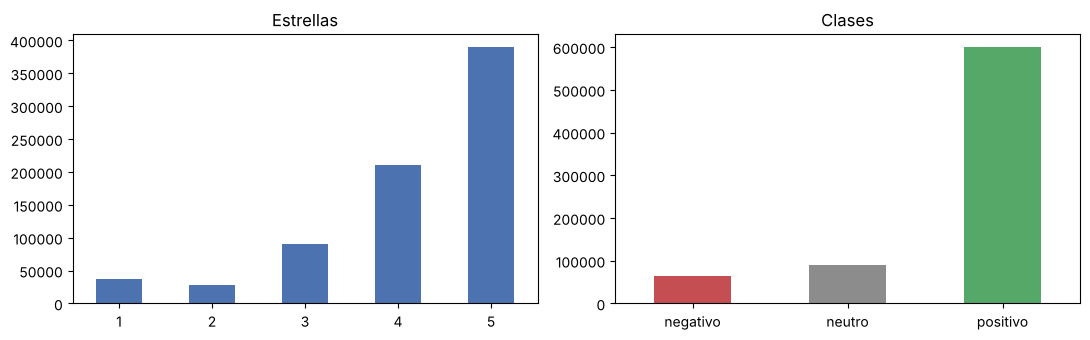

,%
label,
negativo,8.6
neutro,11.9
positivo,79.4


In [4]:
MAPA = {1: "negativo", 2: "negativo", 3: "neutro", 4: "positivo", 5: "positivo"}
df["label"] = df["score"].astype(int).map(MAPA)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["score"].astype(int).value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0", title="Estrellas")
clases = df["label"].value_counts()[["negativo", "neutro", "positivo"]]
clases.plot.bar(ax=ax[1], color=["#C44E52", "#8C8C8C", "#55A868"], title="Clases")
for a in ax:
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

(clases / clases.sum() * 100).round(1).to_frame("%")

**Hallazgo:** desbalance fuerte, cerca del **79 % positivas**. Un modelo que siempre diga "positivo" tendría ~79 % de accuracy sin aprender nada.  
**Decisión:** muestra balanceada (20 000 por clase) y **F1-macro** como métrica principal en lugar de accuracy.

### 1.3 Longitud de los textos

count    755066.0
mean         14.4
std          23.3
min           1.0
5%            1.0
25%           3.0
50%           7.0
75%          16.0
95%          51.0
max        1732.0
Name: n_palabras, dtype: float64

Reseñas con menos de 3 palabras: 22.1%


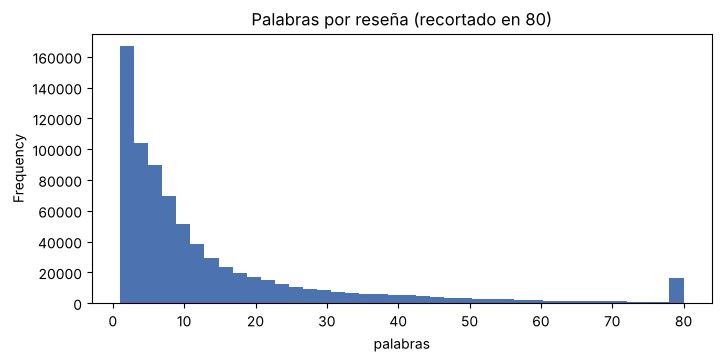

In [5]:
df["n_palabras"] = df["review"].str.split().str.len()
print(df["n_palabras"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(1))
print(f"\nReseñas con menos de 3 palabras: {(df['n_palabras'] < 3).mean():.1%}")

df["n_palabras"].clip(upper=80).plot.hist(bins=40, figsize=(8, 3.5), color="#4C72B0",
                                          title="Palabras por reseña (recortado en 80)")
plt.xlabel("palabras")
plt.show()

**Hallazgo:** las reseñas son muy cortas (mediana ≈ 7 palabras) y ~22 % tiene 1 o 2 palabras ("Bueno", "Excelente").  
**Decisión:** se filtran las reseñas con menos de 3 palabras, porque aportan muy poca información a TF-IDF.

### 1.4 Duplicados y etiquetas contradictorias

In [6]:
clave = df["review"].str.lower()
print("Filas duplicadas:", clave.duplicated().sum())
print("\nTextos más repetidos:")
print(clave.value_counts().head(5))

etiquetas = df.groupby(clave)["label"].nunique()
print("\nTextos con etiquetas contradictorias:", (etiquetas > 1).sum())

Filas duplicadas: 190336

Textos más repetidos:


review
excelente         9706
muy bueno         8939
bueno             7970
rico              4742
buena atención    4723
Name: count, dtype: int64



Textos con etiquetas contradictorias: 4987


**Hallazgo:** muchos textos repetidos, y algunos aparecen con estrellas distintas (ruido en la etiqueta).  
**Decisión:** se eliminan los contradictorios y se deduplica **antes** de dividir en train/test, para evitar fuga de datos.

### 1.5 Palabras más frecuentes por clase

Se calculan sobre la muestra procesada (`data/processed/train.csv`), ya normalizada y sin stop words.

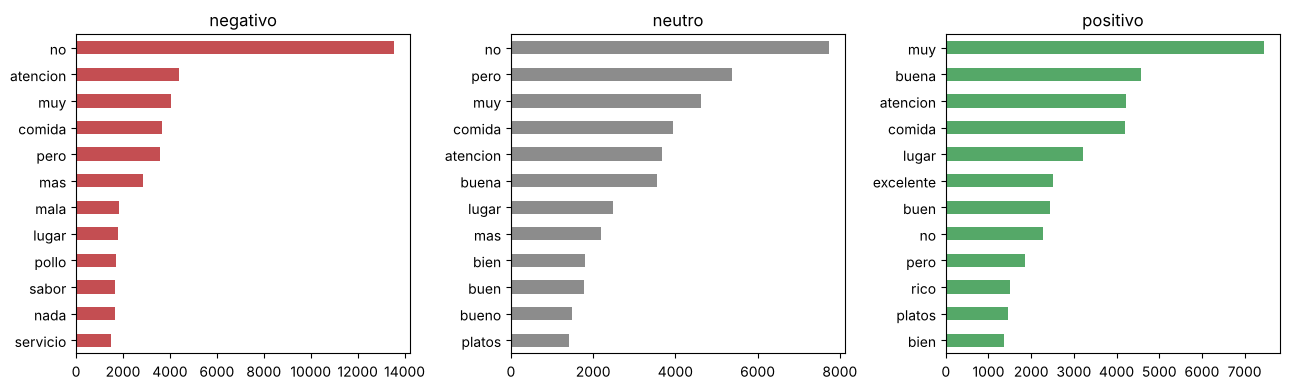

In [7]:
train = pd.read_csv(RAIZ / "data" / "processed" / "train.csv")
train["tokens"] = train["review"].map(lambda t: quitar_stop_words(tokenizar(normalizar(t))))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
colores = {"negativo": "#C44E52", "neutro": "#8C8C8C", "positivo": "#55A868"}
for i, clase in enumerate(["negativo", "neutro", "positivo"]):
    conteo = Counter(t for toks in train.loc[train["label"] == clase, "tokens"] for t in toks)
    top = pd.Series(dict(conteo.most_common(12))).sort_values()
    top.plot.barh(ax=ax[i], color=colores[clase], title=clase)
plt.tight_layout()
plt.show()

**Hallazgos:**
- **"no"** es la palabra más frecuente en las negativas (unas 6 veces más que en las positivas). Confirma que hay que **conservarla** en el paso de stop words.
- **"pero"** domina en las neutras: son reseñas que mezclan elogio y queja (*"rico pero caro"*).
- Las negativas tienen "mala" y "nada"; las positivas, "excelente" y "rico".
- Palabras como "comida", "atencion" y "lugar" aparecen en las tres clases: hablan del tema, no del sentimiento.

### 1.6 Resumen del dataset final

Números generados por `python -m src.data.prepare`:

In [8]:
import json
print(json.dumps(json.loads((RAIZ / "data" / "processed" / "stats.json").read_text(encoding="utf-8")),
                 indent=2, ensure_ascii=False))

{
  "filas_originales": 1258435,
  "con_texto": 755066,
  "con_3_o_mas_palabras": 588340,
  "textos_contradictorios_quitados": 2715,
  "sin_duplicados": 537838,
  "disponibles_por_clase": {
    "positivo": 415597,
    "neutro": 67820,
    "negativo": 54421
  },
  "n_por_clase": 20000,
  "min_palabras": 3,
  "semilla": 42,
  "train": 48000,
  "test": 12000,
  "train_por_clase": {
    "positivo": 16000,
    "neutro": 16000,
    "negativo": 16000
  },
  "test_por_clase": {
    "neutro": 4000,
    "negativo": 4000,
    "positivo": 4000
  }
}


## 2. Pipeline de NLP: ejemplos antes / después

Todas las funciones vienen de `src/nlp/preprocess.py`, el mismo código que usa el entrenamiento y la API.

### 2.1 Normalización
Se eliminan: mayúsculas, tildes (se **conserva la ñ**: año ≠ ano), URLs, números, signos, emojis y letras repetidas de más.

In [9]:
ejemplos = [
    "¡¡La comida estuvo RIQUÍSIMAAA!! 10/10, volveré 😍",
    "No me gustó, el año pasado era mejor. Ver: https://tripadvisor.com",
    "Atención pésima... esperamos 45 min por un pingüino de helado",
]
pd.DataFrame({"antes": ejemplos, "después": [normalizar(t) for t in ejemplos]})

,antes,después
0,"¡¡La comida estuvo RIQUÍSIMAAA!! 10/10, volveré 😍",la comida estuvo riquisimaa volvere
1,"No me gustó, el año pasado era mejor. Ver: https://tripadvisor.com",no me gusto el año pasado era mejor ver
2,Atención pésima... esperamos 45 min por un pingüino de helado,atencion pesima esperamos min por un pinguino de helado


### 2.2 Tokenización — casos difíciles del dominio
Después de normalizar ya no quedan signos, así que basta con separar por espacios.

In [10]:
dificiles = [
    "Buenazo!!! 👌👌",
    "Precio/calidad: 8/10",
    "Riquíiiisimo el lomo saltado",
    "Atención: mala. Comida: buena.",
    "100% recomendado!!!",
]
pd.DataFrame({"antes": dificiles, "tokens": [tokenizar(normalizar(t)) for t in dificiles]})

,antes,tokens
0,Buenazo!!! 👌👌,[buenazo]
1,Precio/calidad: 8/10,"[precio, calidad]"
2,Riquíiiisimo el lomo saltado,"[riquiisimo, el, lomo, saltado]"
3,Atención: mala. Comida: buena.,"[atencion, mala, comida, buena]"
4,100% recomendado!!!,[recomendado]


Se ven problemas típicos de reseñas: emojis, números con barra, letras estiradas y signos pegados. Todos quedan resueltos por la normalización previa.

### 2.3 Stop words
Se usa la lista de NLTK en español, pero se **conservan** palabras que cambian el sentimiento:

In [11]:
print("Stop words usadas:", len(STOP_WORDS))
print("Conservadas a propósito:", sorted(CONSERVAR))

casos = ["No me gustó nada la comida", "Muy rico pero caro", "Sin sabor y nunca volvería"]
filas = []
for t in casos:
    tokens = tokenizar(normalizar(t))
    filas.append({"antes": tokens, "después": quitar_stop_words(tokens)})
pd.DataFrame(filas, index=casos)

Stop words usadas: 297
Conservadas a propósito: ['mas', 'mucho', 'muy', 'nada', 'ni', 'no', 'nunca', 'pero', 'poco', 'sin', 'tampoco']


,antes,después
No me gustó nada la comida,"[no, me, gusto, nada, la, comida]","[no, gusto, nada, comida]"
Muy rico pero caro,"[muy, rico, pero, caro]","[muy, rico, pero, caro]"
Sin sabor y nunca volvería,"[sin, sabor, y, nunca, volveria]","[sin, sabor, nunca, volveria]"


**Justificación:** si se quitara "no", la reseña *"No me gustó nada"* quedaría como *"gusto"*, que parece positiva.
Lo mismo con "sin", "nunca", "muy", "poco" y "pero" (contraste: *"rico pero caro"*).

### 2.4 Stemming vs. lematización
*Pendiente: se agrega con la rama `feature/nlp-stem-lema`.*

## 3. Experimentos
*Pendiente: se completa en la etapa de modelos (n-gramas, TF-IDF, Naive Bayes vs. Regresión Logística y análisis de errores).*